# Banking Fraud & Transaction Intelligence
**Python · pandas · SQL · Tableau**

**Business question:** What transaction patterns may indicate risk, and how useful are simple review rules?

**Data:** First 300,000 rows of the [PaySim synthetic financial transactions dataset](https://www.kaggle.com/datasets/ealaxi/paysim1). These are simulated transactions, **not real bank records**. This is not a random sample, and amounts are in dataset units (not a claimed currency).

## 1. Load and check data
Download `PS_20174392719_1491204439457_log.csv` and put it in the project’s `data/` folder. Run this notebook from the project folder.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

DATA = Path("data/PS_20174392719_1491204439457_log.csv")

Path("data").mkdir(exist_ok=True)
Path("tableau").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

if not DATA.exists():
    print("CSV not found. Please put your PaySim CSV file in:")
    print(DATA.resolve())
else:
    df = pd.read_csv(DATA, nrows=300000)

    print("Rows loaded:", len(df))
    display(df.head())

    print("Missing values:")
    print(df.isna().sum())

    print("Exact duplicates:", df.duplicated().sum())

Rows loaded: 300000


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64
Exact duplicates: 0


## 2. Validate and prepare data
Check required columns and invalid values before analysis. The `step` field represents a **simulated hour**, not a real clock time.

In [2]:
required = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "nameDest", "isFraud", "isFlaggedFraud"]
missing = []

for col in required:
    if col not in df.columns:
        missing.append(col)

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Missing values in required columns:")
print(df[required].isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

# Check data quality before removing any records
invalid = df[required].isna().any(axis=1) | (df["amount"] < 0) | (df["step"] < 1) | ~df["isFraud"].isin([0, 1])
print("Rows with missing or invalid required values:", invalid.sum())

# In this sample no rows need to be removed
if invalid.sum() > 0:
    raise ValueError("Review invalid rows before continuing; do not remove them automatically.")

df = df.copy()
df["transaction_id"] = range(1, len(df) + 1)
df["day"] = (df["step"] - 1) // 24 + 1
df["hour"] = (df["step"] - 1) % 24
print("Rows ready for analysis:", len(df))

Missing values in required columns:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
nameDest          0
isFraud           0
isFlaggedFraud    0
dtype: int64
Exact duplicate rows: 0
Rows with missing or invalid required values: 0
Rows ready for analysis: 300000


In [3]:
print("Rows ready:", len(df))
print("Missing required values:", df[required].isna().sum().sum())
print("Exact duplicates:", df[required].duplicated().sum())

Rows ready: 300000
Missing required values: 0
Exact duplicates: 0


## 3. Explore transaction patterns
Which transaction types have the highest activity and how many simulated fraud labels occur in each?

Total transactions: 300000
Total amount (dataset units): 52851247926.93
Labeled fraud: 181


,type,transactions,transaction_volume,labeled_fraud,fraud_rate_pct
1,CASH_OUT,105401,2.103662e+10,93,0.088234
4,TRANSFER,24905,1.914814e+10,88,0.353343
0,CASH_IN,63408,1.141453e+10,0,0.000000
3,PAYMENT,104056,1.234202e+09,0,0.000000
2,DEBIT,2230,1.776672e+07,0,0.000000


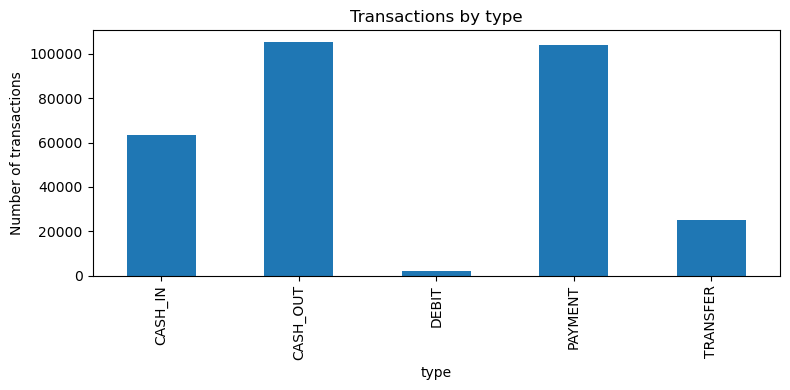

In [4]:
by_type = df.groupby("type", as_index=False).agg(
    transactions=("amount", "size"),
    transaction_volume=("amount", "sum"),
    labeled_fraud=("isFraud", "sum")
)

by_type["fraud_rate_pct"] = by_type["labeled_fraud"] / by_type["transactions"] * 100
print("Total transactions:", len(df))
print("Total amount (dataset units):", round(df["amount"].sum(), 2))
print("Labeled fraud:", int(df["isFraud"].sum()))
display(by_type.sort_values("transaction_volume", ascending=False))
by_type.plot.bar(x="type", y="transactions", legend=False, figsize=(8, 4), title="Transactions by type")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

### Key Finding: Fraud Risk by Transaction Type

CASH_OUT and TRANSFER account for all 181 labeled fraud cases in the analyzed sample.

Although CASH_OUT has more fraudulent transactions (93 vs. 88), TRANSFER has a fraud rate of 0.353%, compared with 0.088% for CASH_OUT — approximately four times higher.

This suggests that transaction volume alone is not enough to assess fraud risk. Fraud rates should also be considered when identifying higher-risk transaction types.

These are **sample-specific synthetic label rates**, not estimates of real-world fraud probability.

## 4. Three illustrative risk indicators

We assign **2 points** for amount ≥100,000 dataset units; **1 point** when the amount exceeds the sender's recorded pre-transaction balance; and **1 point** for TRANSFER or CASH_OUT. A score ≥3 triggers a **review alert**, not a fraud verdict.

These are **illustrative assumptions, not a bank policy or validated risk model**. In particular, an amount exceeding the recorded balance may reflect insufficient funds or simulation behavior; it is not proof of fraud. The 100,000 threshold is not empirically optimized. We do **not** use `isFraud` to create the score.

In [5]:
df["rule_high_amount"] = (df["amount"] >= 100000).astype(int)
df["rule_low_pre_balance"] = (df["oldbalanceOrg"] < df["amount"]).astype(int)
df["rule_transfer"] = df["type"].isin(["TRANSFER", "CASH_OUT"]).astype(int)

df["risk_score"] = 2 * df["rule_high_amount"] + df["rule_low_pre_balance"] + df["rule_transfer"]
df["risk_tier"] = "Low"
df.loc[df["risk_score"] >= 1, "risk_tier"] = "Medium"
df.loc[df["risk_score"] >= 3, "risk_tier"] = "High"
df["rule_alert"] = (df["risk_score"] >= 3).astype(int)

display(df[["type", "amount", "oldbalanceOrg", "risk_score", "risk_tier", "rule_alert"]].head(10))

,type,amount,oldbalanceOrg,risk_score,risk_tier,rule_alert
0,PAYMENT,9839.64,170136.00,0,Low,0
1,PAYMENT,1864.28,21249.00,0,Low,0
2,TRANSFER,181.00,181.00,1,Medium,0
3,CASH_OUT,181.00,181.00,1,Medium,0
4,PAYMENT,11668.14,41554.00,0,Low,0
5,PAYMENT,7817.71,53860.00,0,Low,0
6,PAYMENT,7107.77,183195.00,0,Low,0
7,PAYMENT,7861.64,176087.23,0,Low,0
8,PAYMENT,4024.36,2671.00,1,Medium,0
9,DEBIT,5337.77,41720.00,0,Low,0


## 5. Evaluate alerts

An alert means **review needed**, not confirmed fraud. Compare our alert with PaySim's synthetic `isFraud` label. We examine both detection (recall) and the operational burden from alerts without a fraud label.

In [6]:
found = ((df["isFraud"] == 1) & (df["rule_alert"] == 1)).sum()
missed = ((df["isFraud"] == 1) & (df["rule_alert"] == 0)).sum()
false_alerts = ((df["isFraud"] == 0) & (df["rule_alert"] == 1)).sum()
alerts = int(df["rule_alert"].sum())

print("Rule alerts:", alerts)
print("Labeled fraud flagged:", int(found))
print("Labeled fraud missed:", int(missed))
print("Alerts without fraud label:", int(false_alerts))
      
total_fraud = found + missed

if total_fraud > 0:
    recall = round(found / total_fraud * 100, 2)
    print("Recall (%):", recall)
else:
    print("Recall (%): N/A")  
      
      
if alerts > 0:
    precision = round(found / alerts * 100, 3)
    print("Alert precision (%):", precision)
print("Share of transactions alerted (%):", round(alerts / len(df) * 100, 2))

display(pd.crosstab(df["isFraud"], df["rule_alert"], rownames=["Synthetic fraud label"], colnames=["Our alert"]))

Rule alerts: 112004
Labeled fraud flagged: 87
Labeled fraud missed: 94
Alerts without fraud label: 111917
Recall (%): 48.07
Alert precision (%): 0.078
Share of transactions alerted (%): 37.33


Our alert,0,1
Synthetic fraud label,,
0,187902,111917
1,94,87


### Interpretation: detection versus workload

The rules generated **112,004 alerts from 300,000 transactions (37.33%)**. They flagged **87 of 181 labeled fraud transactions**, giving **48.07% recall**, while **94 labeled fraud transactions were missed**. Only **87 of 112,004 alerts (about 0.078%)** had a fraud label; the other **111,917** did not.

**Business implication:** This illustrative rule set creates a very high review workload while missing more than half of the labeled fraud cases. It should **not** be proposed for deployment as-is. A useful next step would be to test better-supported rules and compare recall, precision, and alert volume. The synthetic labels and non-random sample limit real-world conclusions.

## 6. SQL: transaction summary

Use SQL to independently summarize transaction counts, total value, and labeled fraud by transaction type. The SQL result should agree with the Python summary.

In [7]:
with sqlite3.connect("outputs/banking_intelligence.sqlite") as conn:
    df.to_sql("transactions", conn, if_exists="replace", index=False)
    query = """
    SELECT type,
           COUNT(*) AS transactions,
           ROUND(SUM(amount), 2) AS total_amount,
           SUM(isFraud) AS labeled_fraud
    FROM transactions
    GROUP BY type
    ORDER BY total_amount DESC
    """
    sql_summary = pd.read_sql_query(query, conn)

display(sql_summary)
sql_summary.to_csv("outputs/sql_transaction_summary.csv", index=False)

,type,transactions,total_amount,labeled_fraud
0,CASH_OUT,105401,2.103662e+10,93
1,TRANSFER,24905,1.914814e+10,88
2,CASH_IN,63408,1.141453e+10,0
3,PAYMENT,104056,1.234202e+09,0
4,DEBIT,2230,1.776672e+07,0


## 7. Export data for the existing Tableau dashboards
Keep the original export **filenames and column names**

In [8]:
df["is_merchant"] = df["nameDest"].str.startswith("M").astype(int)
df["amount_band"] = pd.cut(
    df["amount"],
    bins=[-1, 1000, 10000, 50000, 100000, float("inf")],
    labels=["<=1k", "1k–10k", "10k–50k", "50k–100k", ">100k"]
).astype(str)

columns = ["transaction_id", "step", "day", "hour", "type", "amount", "amount_band",
           "nameOrig", "nameDest", "is_merchant", "isFraud", "isFlaggedFraud",
           "risk_score", "risk_tier", "rule_alert", "rule_high_amount",
           "rule_low_pre_balance", "rule_transfer"]
df[columns].to_csv("tableau/transactions_dashboard.csv", index=False)

by_type["rule_alerts"] = df.groupby("type")["rule_alert"].sum().reindex(by_type["type"]).values
by_type = by_type[["type", "transactions", "transaction_volume", "labeled_fraud", "rule_alerts", "fraud_rate_pct"]]
by_type.to_csv("tableau/type_metrics.csv", index=False)

daily = df.groupby("day", as_index=False).agg(
    transactions=("amount", "size"), transaction_volume=("amount", "sum"),
    labeled_fraud=("isFraud", "sum"), rule_alerts=("rule_alert", "sum"))
daily["fraud_rate_pct"] = daily["labeled_fraud"] / daily["transactions"] * 100
daily.to_csv("tableau/daily_metrics.csv", index=False)

heatmap = df.groupby(["day", "hour"], as_index=False).agg(
    transactions=("amount", "size"), labeled_fraud=("isFraud", "sum"),
    rule_alerts=("rule_alert", "sum"))
heatmap.to_csv("tableau/risk_heatmap.csv", index=False)

accounts = pd.DataFrame({"account_id": pd.concat([df["nameOrig"], df["nameDest"]]).drop_duplicates().sort_values().values})
accounts["account_type"] = "Customer-like"
accounts.loc[accounts["account_id"].str.startswith("M"), "account_type"] = "Merchant"
accounts.to_csv("tableau/accounts.csv", index=False)

types = pd.DataFrame({"type": sorted(df["type"].unique())})
types["type_group"] = "Other"
types.loc[types["type"].isin(["TRANSFER", "CASH_OUT"]), "type_group"] = "Movement"
types.to_csv("tableau/transaction_types.csv", index=False)

print("Six Tableau CSV files saved in tableau/")

Six Tableau CSV files saved in tableau/


## 8. Business conclusion

- **Transaction patterns:** CASH_OUT has the most labeled fraud cases (**93**) and TRANSFER has **88**. However, TRANSFER's labeled fraud rate (**0.353%**) is about **4 times** CASH_OUT's (**0.088%**). Counts and rates tell different stories.
- **Risk rules:** Our illustrative scoring rules flag **37.33%** of transactions, identify **48.07%** of labeled fraud, and have only about **0.078% alert precision**. This is not an acceptable operational balance without substantial improvement.
- **Practical lesson:** An alert is a request for review, not a confirmed fraud finding. A useful monitoring system must balance detection with false alerts and staff capacity.
- **Limitations:** PaySim is synthetic; the first 300,000 rows are not a random sample of the dataset or representative of real banking. Amounts are dataset units. The `hour` field is simulated time, not a verified clock hour. `isFraud` is the synthetic label, `isFlaggedFraud` is PaySim's flag, and `rule_alert` is our own rule.
